# NovaAML — phân tích mạng lưới rửa tiền trên dữ liệu IBM AML

Notebook đi cùng ứng dụng `app.py`. Toàn bộ logic nằm ở `aml_core.py`, nên con số ở đây và trên app là một.

**Bối cảnh.** Ngân hàng Việt Nam đã có hệ thống giám sát giao dịch lõi (TMS) sinh cảnh báo theo quy tắc từng giao dịch,
và đã kết nối SIMO của NHNN để báo cáo/tra cứu tài khoản nghi ngờ gian lận. Thứ còn thiếu là cái nhìn **mạng lưới**:
một tài khoản riêng lẻ trông bình thường, nhưng cùng 6 tài khoản khác lại tạo thành vòng tròn hoặc gom–rải tiền.
NovaAML là lớp phân tích đồ thị đặt lên trên TMS và SIMO, không thay thế chúng.

**Dữ liệu.** IBM Transactions for Anti Money Laundering (Kaggle, `ealtman2019`), bản `HI-Small`: dữ liệu tổng hợp,
có nhãn rửa tiền cho từng giao dịch và file mô tả từng vụ theo mẫu hình. Tải thẳng từ Kaggle bằng `kagglehub`, không cần API key.

## 1. Kế hoạch phân tích (khoá trước khi xem kết quả)

| Thành phần | Lựa chọn |
|---|---|
| Đơn vị phân tích | Tài khoản. Nhãn = có ít nhất một giao dịch rửa tiền (gửi hoặc nhận) |
| Quy đổi | Tỷ giá ngầm định trong dữ liệu → USD → VND theo 26.000 VND/USD (giả định) |
| Dấu hiệu | Rải tiền, gom tiền (≥5 đối tác/72h) · vòng tròn 2–6 bước trong 7 ngày · chuyển tiếp nhanh (ra/vào 0,9–1,1 trong 48h, ≥100 triệu) · chia nhỏ ≥3 GD trong [340, 400) triệu/72h · đổi tiền tệ hoặc Bitcoin |
| Điểm | 0–100, trọng số 20/20/25/15/15/5. Ngưỡng cảnh báo 50 |
| SIMO | Mô phỏng: 10% tài khoản rửa tiền + 0,05% tài khoản sạch. Đánh giá chính **không** dùng SIMO để tránh rò nhãn |
| Đối chứng | Điểm của `demo1.py` gốc (bậc + tổng tiền) |
| Chỉ số | PR-AUC (chính, vì nhãn rất lệch), ROC-AUC, độ chính xác trong top-k, độ phủ ở ngưỡng 50, độ phủ theo mẫu hình |

Kế hoạch đầy đủ: `log/plans/2026-11-01_aml-streamlit-vn.md`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
import aml_core as core

OUT = ROOT / "output"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e9e7", "axes.edgecolor": "#9aa39f",
                     "font.size": 10})
INK, ACCENT, MUTED = "#141716", "#0b6e5f", "#9aa39f"
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Tải dữ liệu từ Kaggle

In [2]:
trans_path, pat_path = core.download_raw()   # lần đầu ~475 MB, sau đó dùng cache của kagglehub
df = core.load_transactions(trans_path)
rates = core.usd_rates(df)
df = core.add_vnd(df, rates)
print(f"{len(df):,} giao dịch · {df.is_laundering.sum():,} có nhãn rửa tiền ({df.is_laundering.mean():.3%})")
print("Từ", df.ts.min(), "đến", df.ts.max())
df.head()

C:\Users\hoang\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.3.0)/charset_normalizer (3.4.2) doesn't match a supported version!
  warnings.warn(
C:\Users\hoang\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


5,078,345 giao dịch · 5,177 có nhãn rửa tiền (0.102%)
Từ 2022-09-01 00:00:00 đến 2022-09-18 16:18:00


,ts,from_bank,from_acct,to_bank,to_acct,amt_recv,cur_recv,amt_paid,cur_paid,fmt,is_laundering,amt_vnd
0,2022-09-01 00:20:00,010,8000EBD30,010,8000EBD30,"3,697.340",US Dollar,"3,697.340",US Dollar,Reinvestment,0,"96,130,840.000"
1,2022-09-01 00:20:00,03208,8000F4580,001,8000F5340,0.010,US Dollar,0.010,US Dollar,Cheque,0,260.000
2,2022-09-01 00:00:00,03209,8000F4670,03209,8000F4670,"14,675.570",US Dollar,"14,675.570",US Dollar,Reinvestment,0,"381,564,820.000"
3,2022-09-01 00:02:00,012,8000F5030,012,8000F5030,"2,806.970",US Dollar,"2,806.970",US Dollar,Reinvestment,0,"72,981,220.000"
4,2022-09-01 00:06:00,010,8000F5200,010,8000F5200,"36,682.970",US Dollar,"36,682.970",US Dollar,Reinvestment,0,"953,757,220.000"


In [3]:
pd.Series(rates, name="USD / 1 đơn vị").sort_values(ascending=False).to_frame()

,USD / 1 đơn vị
Bitcoin,"11,874.402"
UK Pound,1.292
Euro,1.172
Swiss Franc,1.093
US Dollar,1.000
Canadian Dollar,0.758
Australian Dollar,0.708
Shekel,0.296
Saudi Riyal,0.267
Brazil Real,0.177


## 3. Mô tả dữ liệu

Tỷ lệ rửa tiền theo hình thức thanh toán, và vị trí của ngưỡng 400 triệu đồng.

In [4]:
by_fmt = (df.groupby("fmt", observed=True)
            .agg(so_gd=("is_laundering", "size"), ty_le_rua_tien=("is_laundering", "mean"),
                 trung_vi_vnd=("amt_vnd", "median"))
            .sort_values("ty_le_rua_tien", ascending=False))
by_fmt.index = by_fmt.index.map(lambda f: core.FORMAT_VI.get(f, f))
by_fmt.style.format({"so_gd": "{:,.0f}", "ty_le_rua_tien": "{:.3%}", "trung_vi_vnd": "{:,.0f}"})

,so_gd,ty_le_rua_tien,trung_vi_vnd
fmt,,,
Chuyển khoản tự động,"600,797",0.746%,"29,548,220"
Bitcoin,"146,091",0.038%,"21,583,318"
Tiền mặt,"490,891",0.022%,"23,225,800"
Séc,"1,864,331",0.017%,"28,585,093"
Thẻ tín dụng,"1,323,324",0.016%,"15,831,920"
Tái đầu tư,"481,056",0.000%,"28,916,089"
Điện chuyển tiền,"171,855",0.000%,"13,010,663"


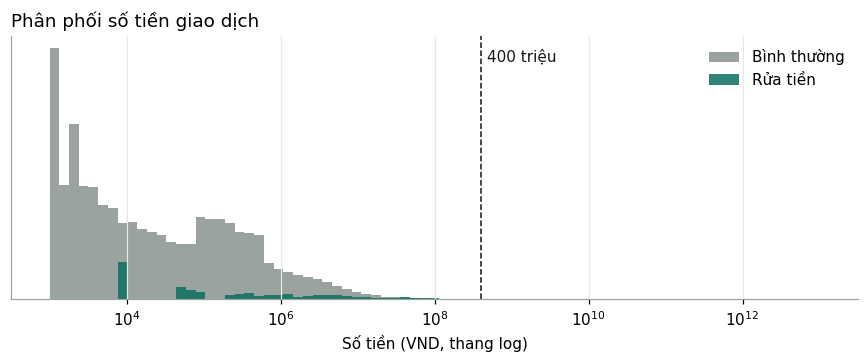

GD ≥ 400 triệu: 15.5% · trong vùng 340–400 triệu: 1.31%


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(3, 13, 80)
ax.hist(df.loc[df.is_laundering == 0, "amt_vnd"], bins=bins, color=MUTED, density=True, label="Bình thường")
ax.hist(df.loc[df.is_laundering == 1, "amt_vnd"], bins=bins, color=ACCENT, density=True, alpha=.85, label="Rửa tiền")
ax.axvline(core.LARGE_VALUE_VND, color=INK, ls="--", lw=1); ax.text(core.LARGE_VALUE_VND * 1.2, ax.get_ylim()[1] * .9, "400 triệu", color=INK)
ax.set_xscale("log"); ax.set_xlabel("Số tiền (VND, thang log)"); ax.set_yticks([]); ax.legend(frameon=False)
ax.set_title("Phân phối số tiền giao dịch", loc="left")
fig.tight_layout(); fig.savefig(FIG / "phan_phoi_so_tien.png"); plt.show()
print(f"GD ≥ 400 triệu: {(df.amt_vnd >= core.LARGE_VALUE_VND).mean():.1%} · "
      f"trong vùng 340–400 triệu: {df.amt_vnd.between(core.STRUCT_LOW_VND, core.LARGE_VALUE_VND, inclusive='left').mean():.2%}")

## 4. Đặc trưng mạng lưới và điểm rủi ro

Bỏ giao dịch tự chuyển (cùng tài khoản). Tìm chu trình loại bỏ tài khoản có hơn 50 đối tác — thường là doanh nghiệp lớn —
để việc liệt kê chu trình không bùng nổ.

In [6]:
%%time
acc = core.score(core.account_features(df))
laundering = core.account_labels(df)
acc["is_laundering"] = acc.index.isin(laundering)
print(f"{len(acc):,} tài khoản · {acc.is_laundering.sum():,} liên quan rửa tiền ({acc.is_laundering.mean():.3%})")

515,080 tài khoản · 6,357 liên quan rửa tiền (1.234%)
CPU times: total: 1min 1s
Wall time: 1min 4s


In [7]:
rows = []
for f, label in core.FLAG_LABELS.items():
    m = acc[f"s_{f}"] >= 1
    rows.append({"dấu hiệu": label, "trọng số": core.WEIGHTS[f], "số TK bị gắn": int(m.sum()),
                 "trong đó rửa tiền": int((m & acc.is_laundering).sum()),
                 "độ chính xác": (m & acc.is_laundering).sum() / max(m.sum(), 1),
                 "độ phủ": (m & acc.is_laundering).sum() / acc.is_laundering.sum()})
signals = pd.DataFrame(rows); signals

,dấu hiệu,trọng số,số TK bị gắn,trong đó rửa tiền,độ chính xác,độ phủ
0,Rải tiền (fan-out),20,17224,493,0.029,0.078
1,Gom tiền (fan-in),20,8479,607,0.072,0.095
2,Vòng tròn khép kín,25,4913,482,0.098,0.076
3,Chuyển tiếp nhanh,15,4431,238,0.054,0.037
4,Chia nhỏ sát ngưỡng 400 triệu,15,4692,138,0.029,0.022
5,Đổi tiền tệ / tài sản mã hoá,5,23447,1598,0.068,0.251


## 5. Đánh giá so với nhãn IBM (một lần, theo kế hoạch)

In [8]:
y = acc.is_laundering.astype(int)
base = core.degree_baseline(acc)

def report(score, name):
    order = score.sort_values(ascending=False).index
    r = {"điểm": name, "PR-AUC": average_precision_score(y, score), "ROC-AUC": roc_auc_score(y, score)}
    for k in (100, 1000, 5000):
        r[f"chính xác@{k}"] = y.loc[order[:k]].mean()
    return r

alert = acc.risk >= core.ALERT_THRESHOLD
evaluation = pd.DataFrame([report(acc.risk, "NovaAML (mẫu hình)"), report(base, "demo1 gốc (bậc + tiền)")])
evaluation.loc[len(evaluation)] = {"điểm": "tỷ lệ nền (chọn ngẫu nhiên)", "PR-AUC": y.mean(), "ROC-AUC": .5,
                                   "chính xác@100": y.mean(), "chính xác@1000": y.mean(), "chính xác@5000": y.mean()}
print(f"Ở ngưỡng {core.ALERT_THRESHOLD}: {alert.sum():,} cảnh báo, độ chính xác {acc[alert].is_laundering.mean():.1%}, "
      f"độ phủ {acc[alert].is_laundering.sum() / y.sum():.1%}")
evaluation

Ở ngưỡng 50: 802 cảnh báo, độ chính xác 14.1%, độ phủ 1.8%


,điểm,PR-AUC,ROC-AUC,chính xác@100,chính xác@1000,chính xác@5000
0,NovaAML (mẫu hình),0.038,0.732,0.190,0.135,0.089
1,demo1 gốc (bậc + tiền),0.027,0.713,0.200,0.054,0.041
2,tỷ lệ nền (chọn ngẫu nhiên),0.012,0.500,0.012,0.012,0.012


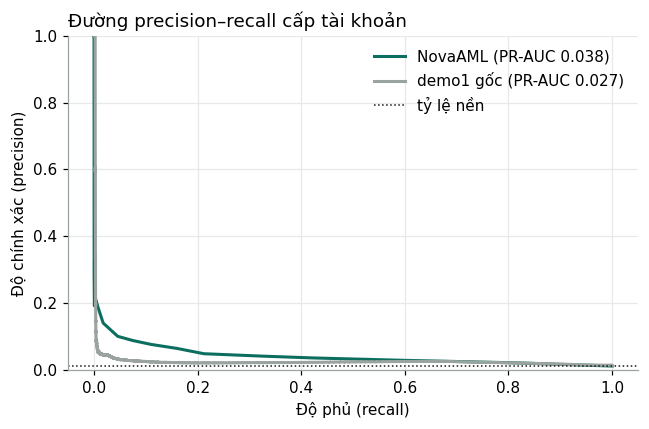

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
for s, name, col in ((acc.risk, "NovaAML", ACCENT), (base, "demo1 gốc", MUTED)):
    p, r, _ = precision_recall_curve(y, s)
    ax.plot(r, p, color=col, lw=2, label=f"{name} (PR-AUC {average_precision_score(y, s):.3f})")
ax.axhline(y.mean(), color=INK, ls=":", lw=1, label="tỷ lệ nền")
ax.set_xlabel("Độ phủ (recall)"); ax.set_ylabel("Độ chính xác (precision)"); ax.set_ylim(0, 1)
ax.legend(frameon=False); ax.set_title("Đường precision–recall cấp tài khoản", loc="left")
fig.tight_layout(); fig.savefig(FIG / "precision_recall.png"); plt.show()

### Độ phủ theo loại mẫu hình

Dùng file `HI-Small_Patterns.txt`: mỗi tài khoản trong một vụ được gán loại mẫu hình của vụ đó.

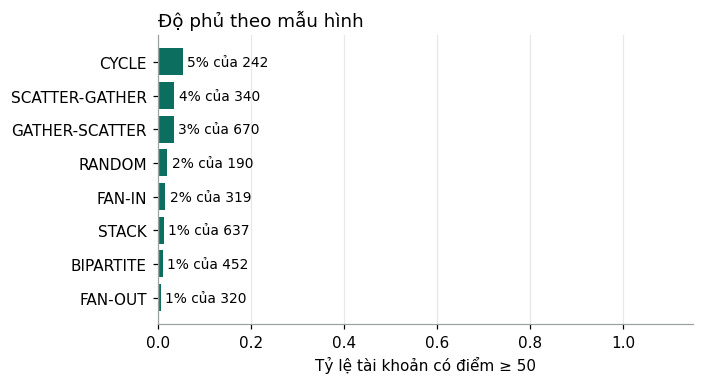

,so_tk,do_phu,diem_tb
pattern,,,
FAN-OUT,320,0.006,11.328
BIPARTITE,452,0.011,13.197
STACK,637,0.013,15.330
FAN-IN,319,0.016,14.734
RANDOM,190,0.021,17.053
GATHER-SCATTER,670,0.034,12.500
SCATTER-GATHER,340,0.035,17.824
CYCLE,242,0.054,23.264


In [10]:
pat = core.parse_patterns(pat_path)
first = pd.concat([pat[["from_acct", "pattern"]].set_axis(["a", "p"], axis=1),
                   pat[["to_acct", "pattern"]].set_axis(["a", "p"], axis=1)]).drop_duplicates("a").set_index("a").p
acc["pattern"] = first
by_pattern = (acc[acc.pattern.notna()].assign(bat_duoc=lambda d: d.risk >= core.ALERT_THRESHOLD)
              .groupby("pattern").agg(so_tk=("bat_duoc", "size"), do_phu=("bat_duoc", "mean"),
                                      diem_tb=("risk", "mean")).sort_values("do_phu"))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(by_pattern.index, by_pattern.do_phu, color=ACCENT)
for i, (v, n) in enumerate(zip(by_pattern.do_phu, by_pattern.so_tk)):
    ax.text(v + .01, i, f"{v:.0%} của {n}", va="center", fontsize=9)
ax.set_xlim(0, 1.15); ax.set_xlabel(f"Tỷ lệ tài khoản có điểm ≥ {core.ALERT_THRESHOLD}")
ax.set_title("Độ phủ theo mẫu hình", loc="left"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "do_phu_theo_mau_hinh.png"); plt.show()
by_pattern

## 6. Lớp SIMO mô phỏng

Thêm điểm ưu tiên: +25 nếu tài khoản có trong danh sách SIMO, +10 nếu cách tài khoản SIMO tối đa 2 bước giao dịch.
Để không tự chấm điểm cho mình, đánh giá phần này **loại bỏ** chính các tài khoản được gieo vào SIMO.

In [11]:
simo = core.simulate_simo(acc, laundering)
acc = core.simo_overlay(df, acc, simo)
rest = acc[~acc.simo_hit]
print(f"SIMO mô phỏng: {len(simo):,} tài khoản; {acc.simo_near.sum():,} tài khoản cách ≤ 2 bước")
pd.DataFrame([
    {"điểm": "mẫu hình", "PR-AUC": average_precision_score(rest.is_laundering, rest.risk)},
    {"điểm": "mẫu hình + lân cận SIMO", "PR-AUC": average_precision_score(rest.is_laundering, rest.priority)},
])

SIMO mô phỏng: 889 tài khoản; 56,088 tài khoản cách ≤ 2 bước


,điểm,PR-AUC
0,mẫu hình,0.034
1,mẫu hình + lân cận SIMO,0.045


## 7. Ví dụ: mạng lưới quanh cảnh báo ưu tiên cao nhất

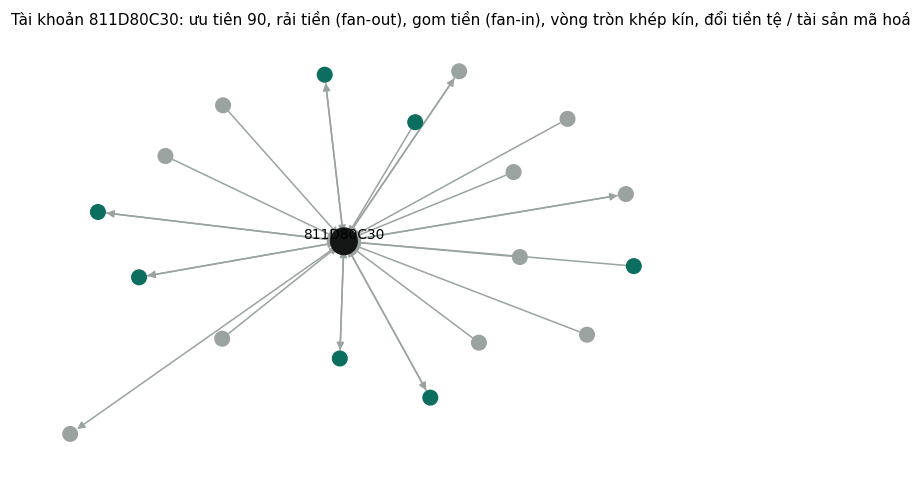

In [12]:
import networkx as nx
top_acc = acc.sort_values(["priority", "out_vnd"], ascending=False).index[0]
ext = df[df.from_acct != df.to_acct]
e = ext[(ext.from_acct == top_acc) | (ext.to_acct == top_acc)]
G = nx.from_pandas_edgelist(e.groupby(["from_acct", "to_acct"]).amt_vnd.sum().reset_index(),
                            "from_acct", "to_acct", "amt_vnd", create_using=nx.DiGraph)
pos = nx.spring_layout(G, seed=1)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color=MUTED, arrows=True, arrowsize=10, node_size=120)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[300 if n == top_acc else 90 for n in G],
                       node_color=[INK if n == top_acc else (ACCENT if acc.loc[n, "priority"] >= core.ALERT_THRESHOLD else MUTED) for n in G])
nx.draw_networkx_labels(G, pos, labels={top_acc: top_acc}, font_size=9, ax=ax, verticalalignment="bottom")
ax.set_axis_off(); ax.set_title(f"Tài khoản {top_acc}: ưu tiên {acc.loc[top_acc, 'priority']:.0f}, "
                                f"{', '.join(core.FLAG_LABELS[x].lower() for x in acc.loc[top_acc, 'signals'])}", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "vi_du_mang_luoi.png"); plt.show()

## 8. Xuất sản phẩm đầu ra

In [13]:
alerts = (acc[acc.priority >= core.ALERT_THRESHOLD]
          .assign(dau_hieu=lambda d: d.signals.apply(lambda s: "; ".join(core.FLAG_LABELS[x] for x in s)))
          .sort_values("priority", ascending=False)
          [["bank", "priority", "risk", "simo_hit", "simo_near", "dau_hieu", "out_n", "in_n", "out_vnd", "in_vnd"]])
alerts.to_csv(OUT / "canh_bao_uu_tien.csv", encoding="utf-8-sig")
summary = {"evaluation": evaluation.to_dict("records"), "signals": signals.to_dict("records"),
           "by_pattern": by_pattern.reset_index().to_dict("records"),
           "n_alerts": int(len(alerts)), "threshold": core.ALERT_THRESHOLD, "weights": core.WEIGHTS}
(OUT / "danh_gia.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print(f"Đã ghi {len(alerts):,} cảnh báo vào output/canh_bao_uu_tien.csv, hình vào output/figures/")

Đã ghi 2,006 cảnh báo vào output/canh_bao_uu_tien.csv, hình vào output/figures/


## 9. Kết quả chính

- **Điểm mẫu hình tốt hơn điểm gốc của demo1, nhưng còn xa mức dùng được một mình.** PR-AUC 0,038 so với 0,027 (demo1) và 0,012 (chọn ngẫu nhiên).
  Trong 1.000 tài khoản điểm cao nhất có 13,5% liên quan rửa tiền, gấp khoảng 11 lần tỷ lệ nền và 2,5 lần điểm gốc.
- **Ở ngưỡng 50, độ phủ rất thấp (1,8%).** 802 cảnh báo, độ chính xác 14,1%. Lý do chính: nhãn cấp tài khoản gán cho *mọi* bên tham gia một vụ,
  còn phần lớn bên nhận trong một vụ rải tiền chỉ có một giao dịch và không mang dấu hiệu nào khi đứng riêng.
  Đây đúng là chỗ phân tích mạng lưới (lan truyền rủi ro từ tài khoản đã bị gắn cờ sang đối tác) có thể bù vào. Đó sẽ là một **phân tích mới** cần kế hoạch riêng, không phải chỉnh trọng số hiện tại.
- **Vòng tròn là dấu hiệu chính xác nhất (9,8%)**; đổi tiền tệ phủ rộng nhất (25%) nhưng nhiễu.
- **Chia nhỏ sát 400 triệu gần như không có tác dụng trên dữ liệu này** (độ chính xác 2,9%), như dự đoán: bộ IBM không mô phỏng ngưỡng của Việt Nam.
- **Lớp SIMO giúp**: thêm điểm lân cận SIMO nâng PR-AUC từ 0,034 lên 0,045 trên các tài khoản *không* nằm trong danh sách gieo.

Mọi con số trên lấy từ lần chạy này với tham số đã khoá; không tham số nào được chỉnh sau khi xem kết quả.

## 10. Hạn chế

- Dữ liệu IBM là **tổng hợp** và không mô phỏng ngưỡng 400 triệu của Việt Nam; dấu hiệu chia nhỏ vì vậy ít có tác dụng ở đây,
  nhưng vẫn cần với dữ liệu thật.
- Bộ HI-Small có tỷ lệ rửa tiền cao hơn thực tế nhiều. Thử lại với `LI-Small` (`python prepare_data.py LI-Small`) trước khi rút kết luận.
- Ngưỡng, cửa sổ thời gian, trọng số được chọn trước, chưa tối ưu. Nếu điều chỉnh sau khi xem kết quả, coi đó là phân tích mới và ghi lý do.
- Chu trình chỉ tìm tới 6 bước và bỏ tài khoản trên 50 đối tác; các vòng dài hơn sẽ bị bỏ sót.
- Kết nối TMS và SIMO là mô phỏng. Quy định pháp lý (ngưỡng, mẫu báo cáo, thời hạn) cần bộ phận pháp chế đối chiếu văn bản hiện hành.